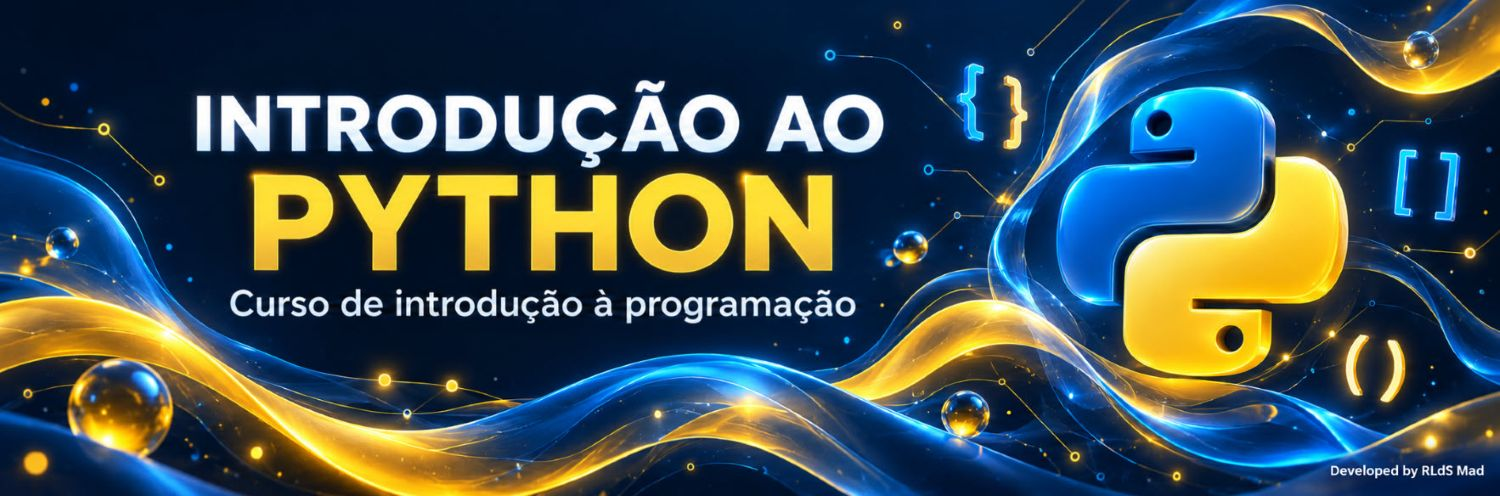

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_3_ia/RLdS_N3_02_Estatistica_Descritiva_Bibliotecas.ipynb)


# Nível IA · Módulo 2 – Estatística descritiva com NumPy, pandas e SciPy
## Os exercícios 1 a 12, agora com as bibliotecas

No módulo 1 resolveste os exercícios 1 a 12 da disciplina de Fundamentos de Estatística com Python puro: cada fórmula era uma função escrita por ti. Na prática, ninguém reescreve a média ou o desvio-padrão: usam-se bibliotecas testadas e rápidas. Neste módulo resolves **os mesmos exercícios, alínea a alínea**, com NumPy, pandas, SciPy e seaborn.

Depois de cada exercício, uma caixa **«O que mudou em relação ao módulo 1»** resume o que as bibliotecas trouxeram: que funções substituíram, quanto código se poupou e que cuidados é preciso ter. Vais ver que as bibliotecas encurtam muito o código, mas que nem sempre usam por omissão a convenção da disciplina, e que alguns cálculos continuam a precisar de código teu.

No fim, organizas o código num módulo teu, `estatistica.py`, com classes de dados, e escreves testes automáticos que confirmam os valores das soluções oficiais.

> **Objetivos:** resolver exercícios de estatística descritiva com NumPy, pandas e SciPy; controlar as convenções (divisor n − 1, método de quantis, classes [a ; b[); construir tabelas de frequências e de classes com pandas; comparar os coeficientes de assimetria e curtose da disciplina com os de momentos; desenhar histogramas, ogivas e diagramas de extremos e quartis com matplotlib e seaborn; organizar código em classes de dados e num módulo, e testá-lo com `unittest`.

**Pré-requisitos:** o módulo 1 (estatística descritiva com Python puro); os capítulos 20 (Classes e objetos, incluindo `dataclasses`), 21 (Módulos e pacotes), 22 (NumPy), 23 (Pandas básico) e 24 (Visualização de dados).

**Duração sugerida:** 5 a 7 horas.

### Como utilizar
Executa as células por ordem, com `Shift + Enter`. Os dados dos 12 exercícios estão todos na secção «Preparação»: executa-a antes de qualquer outra. Funciona em Jupyter, VS Code e Colab; todas as bibliotecas já vêm instaladas no Colab.

Abre o módulo 1 ao lado deste notebook: as alíneas têm a mesma numeração, por isso podes comparar as duas resoluções. Cada resultado é comparado com o valor oficial; quando uma biblioteca dá outro valor, isso não é um erro, é uma convenção diferente, e o texto explica qual.

### Índice
0. Preparação: bibliotecas e dados dos exercícios
1. Do módulo 1 às bibliotecas: tabela de equivalências
2. Antes de começar: três convenções a controlar
3. Resolução dos exercícios 1 a 12
4. Refatorar e testar: classes, um módulo próprio e `unittest`
5. Experimenta, Verifica o que aprendeste e Leitura recomendada


## 0. Preparação

### 0.1 Bibliotecas


In [1]:
# Executar esta célula

import math
import statistics

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib import cbook
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
print(f"NumPy {np.__version__} | pandas {pd.__version__} | SciPy {scipy.__version__} | seaborn {sns.__version__}")

NumPy 2.5.4 | pandas 3.0.6 | SciPy 1.18.1 | seaborn 0.13.2


### 0.2 Dados dos 12 exercícios

São os mesmos dados do módulo 1. O dicionário `OFICIAL` guarda os valores das soluções oficiais usados para confirmar os resultados, e a função `confere` faz a comparação, como no módulo 1.


In [2]:
# Executar esta célula

# Ex. 1 – Eleições
inscritos, pA, nB, p_abst = 4000, 0.34, 1200, 0.10
# Ex. 2 – Bolsas de estudo
bolsas = [218, 218, 220, 222, 221, 218, 219, 220, 217, 218, 219, 220, 221,
          218, 217, 219, 220, 218, 222, 219, 218, 224, 220, 218, 224]
# Ex. 3 – Completar um quadro (36 notas, F1 = 0,25, n2 = 20)
N3, F1_3, n2_3, limites3 = 36, 0.25, 20, [0, 10, 13, 20]
# Ex. 4 – Contratos por dia
contratos = [12, 10, 12, 11, 11, 5, 7, 7, 10, 10, 8, 8, 7, 7, 5]
# Ex. 5 – Alturas (cm)
alturas = [150, 169, 174, 155, 165, 170, 172, 152, 158, 163, 158, 166, 158, 166,
           170, 171, 162, 171, 161, 154, 168, 161, 164, 166, 164, 162, 156, 167]
# Ex. 6 – Satisfação dos alunos
notas = [2.4, 3.1, 4.5, 4.4, 3.9, 3.5, 3.4, 3.9, 2.4, 2.7, 2.8, 2.3, 4.1, 3.2,
         1.2, 3.8, 2.2, 2.3, 3.4, 2.2, 2.2, 4.1, 3.8, 3.7, 1.9, 3.3, 3.0, 3.0,
         4.0, 1.8, 2.2, 3.6, 1.8, 4.1, 2.8]
# Ex. 7 – Q.I. de 80 crianças
qi = [111, 85, 82, 108, 85, 75, 112, 100, 133, 98, 106, 92, 102, 94, 91, 118,
      77, 94, 121, 100, 107, 115, 109, 100, 97, 102, 98, 101, 88, 104, 67, 111,
      106, 120, 91, 101, 103, 90, 93, 85, 98, 83, 98, 89, 106, 109, 100, 127,
      93, 100, 90, 102, 87, 79, 117, 85, 72, 98, 105, 122, 104, 95, 109, 133,
      116, 103, 56, 88, 107, 107, 94, 94, 99, 102, 108, 87, 80, 80, 119, 93]
# Ex. 8 – Prova de tiro
tiros = [5, 6, 8, 5, 10, 7, 8, 5, 8, 7, 2, 9, 10]
# Ex. 9 – Horas de instrução (tabela valor / n.º)
horas, alunos = [12, 13, 14, 15, 16, 17, 18, 19, 20], [3, 6, 8, 10, 7, 6, 5, 3, 2]
# Ex. 10 – Ocupantes por veículo (tabela valor / n.º)
ocupantes, veiculos = [1, 2, 3, 4], [150, 275, 320, 255]
# Ex. 11 – Composição de iogurtes
naturais = {"proteinas": [6.6, 5.4, 5.4, 6.2, 5.0, 5.6, 5.8],
            "lipidos":   [0.5, 0.5, 3.7, 1.5, 2.3, 0.2, 0.3],
            "hidratos":  [8.4, 5.9, 15.6, 10.4, 6.5, 5.1, 6.2]}
normais = {"proteinas": [5.3, 4.8, 4.7, 5.4, 4.0, 2.8, 3.7, 3.9, 4.5, 3.2, 4.1, 3.7, 5.3],
           "lipidos":   [2.5, 1.4, 2.1, 4.1, 3.0, 0.5, 1.4, 11.5, 2.4, 3.5, 2.8, 3.0, 3.8],
           "hidratos":  [16.9, 22.0, 16.0, 12.0, 20.2, 11.0, 4.4, 12.0, 12.0, 15.0, 10.7, 14.0, 18.0]}
# Ex. 12 – Salários (classes dadas)
limites12 = [250, 500, 750, 1000, 1250, 1500, 1750, 2000]
freqs12 = [60, 150, 230, 70, 43, 32, 15]

# Valores das soluções oficiais
OFICIAL = {
    "4.3 CV (%)": 27.12, "4.5 K": 0.286,
    "5.5 média (classes)": 163.93, "5.5 mediana (classes)": 164.29, "5.5 Q1 (classes)": 159.00,
    "5.5 Q3 (classes)": 169.29, "5.5 1.ª moda (classes)": 162.92, "5.5 2.ª moda (classes)": 167.31,
    "5.5 s": 6.39, "6.4 média (agrupados)": 3.094, "7.2 média": 98.825,
    "8.1 Q1": 5, "8.1 mediana": 7, "8.1 Q3": 8.5,
    "9.1 média": 15.54, "9.2 Q1": 14, "9.2 mediana": 15, "9.2 Q3": 17,
    "10.6 média": 2.68, "10.10 K": 0.333, "11.1 σ (divisor n)": 0.986,
    "11.2 hidratos naturais": 8.30, "11.2 hidratos normais": 14.17,
    "11.2 lípidos naturais": 1.29, "11.2 lípidos normais": 3.23,
    "12.8 média": 892.50, "12.8 mediana": 847.83, "12.8 moda": 829.55, "12.9 s": 347.46, "12.9 CV (%)": 38.93,
}


def confere(chave, obtido, casas=2):
    """Compara um valor com OFICIAL[chave], arredondado a `casas` casas decimais."""
    oficial = OFICIAL[chave]
    marca = "✓" if round(float(obtido), casas) == round(oficial, casas) else "✗"
    print(f"{marca} {chave:<26} obtido {float(obtido):.{casas}f} | oficial {oficial:.{casas}f}")


print("Dados carregados:", len(OFICIAL), "valores oficiais de referência.")

Dados carregados: 30 valores oficiais de referência.


## 1. Do módulo 1 às bibliotecas

Cada função que escreveste no módulo 1 tem um equivalente nas bibliotecas. A coluna da direita é a mais importante: diz o que tens de indicar para obter **a convenção da disciplina**.

| Módulo 1 | Biblioteca | Atenção à convenção |
| --- | --- | --- |
| `media(dados)` | `np.mean(x)`, `serie.mean()` | — |
| `mediana(dados)` | `np.median(x)`, `serie.median()` | — |
| `moda(dados)` | `np.unique(x, return_counts=True)`, `serie.mode()` | `stats.mode` devolve só uma moda |
| `variancia`, `desvio_padrao` | `np.var`, `np.std`, `serie.var()`, `serie.std()` | NumPy usa divisor n por omissão: indica `ddof=1`. O pandas já usa n − 1 |
| `quantil(dados, p)` | `np.quantile(x, p, method="weibull")`, `statistics.quantiles` | o método por omissão do NumPy e do pandas é outro |
| `tabela_frequencias` | `serie.value_counts().sort_index()` e `cumsum()` | — |
| `classes_sturges` | `np.histogram(x, bins=limites)` | `bins="sturges"` do NumPy usa outra fórmula |
| `media_ponderada` | `np.average(x, weights=n)` | — |
| `quantil_classes` | `np.interp` sobre a ogiva | não há função pronta |
| `moda_classes` | — | não há função pronta |
| `coef_variacao` | `stats.variation(x, ddof=1) * 100` | `ddof=1` |
| Pearson, Bowley, K | `stats.skew`, `stats.kurtosis` | medem a forma de outra maneira (momentos) |
| `histograma` | `ax.hist`, `sns.histplot` | passar os limites das classes em `bins` |
| `diagrama_extremos_quartis` | `ax.boxplot`, `sns.boxplot` | quartis pelo método linear por omissão |


## 2. Antes de começar: três convenções a controlar

Há três pontos em que as bibliotecas, por omissão, **não** fazem o que a disciplina faz. São explicados aqui uma vez; nos exercícios basta lembrar-te deles.

### 2.1 O divisor do desvio-padrão (`ddof`)

`np.std` e `np.var` usam por omissão **divisor n** (`ddof=0`, de *delta degrees of freedom*). Para o divisor n − 1 dos slides, indica `ddof=1`. O pandas faz o contrário: `serie.std()` já usa n − 1. Com os contratos do ex. 4:


In [3]:
# Executar esta célula

x = np.array(contratos)
print(f"np.std(x)          = {np.std(x):.4f}   ← divisor n (por omissão)")
print(f"np.std(x, ddof=1)  = {np.std(x, ddof=1):.4f}   ← divisor n − 1 (slides)")
print(f"pd.Series(x).std() = {pd.Series(x).std():.4f}   ← o pandas já usa n − 1")

np.std(x)          = 2.2706   ← divisor n (por omissão)
np.std(x, ddof=1)  = 2.3503   ← divisor n − 1 (slides)
pd.Series(x).std() = 2.3503   ← o pandas já usa n − 1


### 2.2 O método de cálculo dos quantis

Hyndman e Fan (1996) descreveram nove métodos de calcular quantis, usados por diferentes programas. Os mais comuns:

| Método | Posição de Q(p) | Onde aparece |
| --- | --- | --- |
| **Weibull** (tipo 6) | p·(n + 1), com interpolação | **slides da disciplina**, `statistics.quantiles` por omissão, `np.quantile(..., method="weibull")`, Excel `QUARTIL.EXC` |
| **Linear** (tipo 7) | 1 + p·(n − 1), com interpolação | **por omissão** no NumPy, no pandas, no matplotlib e no seaborn; Excel `QUARTIL.INC` e `QUARTIL` |
| Hazen (tipo 5) | p·n + ½ | `method="hazen"` |
| Mediana não enviesada (tipo 8) | p·(n + ⅓) + ⅓ | `method="median_unbiased"`, recomendado por Hyndman e Fan |

A mediana é igual em todos; as diferenças aparecem nos quartis, decis e percentis, sobretudo com poucos dados. A função seguinte calcula Q₁, Me e Q₃ com vários métodos lado a lado:


In [4]:
# Executar esta célula

def comparar_quartis(dados):
    metodos = {
        "slides · statistics.quantiles": statistics.quantiles(dados, n=4),
        "NumPy method='weibull'": np.quantile(dados, [.25, .5, .75], method="weibull"),
        "NumPy por omissão (linear)": np.quantile(dados, [.25, .5, .75]),
        "pandas .quantile()": pd.Series(dados).quantile([.25, .5, .75]).to_numpy(),
        "statistics method='inclusive'": statistics.quantiles(dados, n=4, method="inclusive"),
        "NumPy method='hazen'": np.quantile(dados, [.25, .5, .75], method="hazen"),
        "NumPy method='median_unbiased'": np.quantile(dados, [.25, .5, .75], method="median_unbiased"),
    }
    return pd.DataFrame(metodos, index=["Q1", "Me", "Q3"]).T.round(3)


print("Ex. 4 – Contratos por dia (oficial: Q1 = 7, Me = 8, Q3 = 11)")
comparar_quartis(contratos)

Ex. 4 – Contratos por dia (oficial: Q1 = 7, Me = 8, Q3 = 11)


,Q1,Me,Q3
slides · statistics.quantiles,7.0,8.0,11.000
NumPy method='weibull',7.0,8.0,11.000
NumPy por omissão (linear),7.0,8.0,10.500
pandas .quantile(),7.0,8.0,10.500
statistics method='inclusive',7.0,8.0,10.500
NumPy method='hazen',7.0,8.0,10.750
NumPy method='median_unbiased',7.0,8.0,10.833


Em todo o notebook usamos `np.quantile(x, p, method="weibull")`. Repara que o pandas e o método `"inclusive"` do `statistics` coincidem com o NumPy por omissão: é o mesmo método (tipo 7).

**No Excel:** `QUARTIL.EXC` e `PERCENTIL.EXC` usam o método dos slides; `QUARTIL.INC`, `PERCENTIL.INC` e o antigo `QUARTIL` usam o linear. Do mesmo modo, `DESVPAD.A` divide por n − 1 (como `ddof=1`) e `DESVPAD.P` divide por n.

### 2.3 As classes: regra de Sturges e fecho da última classe

- **Sturges:** `np.histogram(..., bins="sturges")` usa log₂ n + 1, arredondado para cima, e não a fórmula dos slides (1 + 3,3·log₁₀ n, truncada). Dá uma classe a mais. Por isso escrevemos a nossa função `sturges`.
- **Fecho da última classe:** a disciplina usa [a ; b[, mas fecha a última classe para incluir o máximo. `np.histogram` faz exatamente isso. Já `pd.cut(..., right=False)` deixa a última classe aberta e um valor igual ao último limite fica **sem classe** (`NaN`).


In [5]:
# Executar esta célula

def sturges(n):
    """Regra de Sturges dos slides: 1 + 3,3·log10(n), truncada."""
    return int(1 + 3.3 * math.log10(n))


for nome, dados in (("alturas (ex. 5)", alturas), ("notas (ex. 6)", notas), ("Q.I. (ex. 7)", qi)):
    k_numpy = len(np.histogram_bin_edges(dados, bins="sturges")) - 1
    print(f"{nome:16} n = {len(dados):2}   slides: {sturges(len(dados))} classes   NumPy: {k_numpy} classes")

limites7 = 56 + 11 * np.arange(8)
classe = pd.cut(pd.Series(qi), bins=limites7, right=False)
print("\nEx. 7 com pd.cut: ficam sem classe", pd.Series(qi)[classe.isna()].tolist())
print("Ex. 7 com np.histogram:", np.histogram(qi, bins=limites7)[0].tolist(), "→ total", len(qi))

alturas (ex. 5)  n = 28   slides: 5 classes   NumPy: 6 classes
notas (ex. 6)    n = 35   slides: 6 classes   NumPy: 7 classes
Q.I. (ex. 7)     n = 80   slides: 7 classes   NumPy: 8 classes

Ex. 7 com pd.cut: ficam sem classe [133, 133]
Ex. 7 com np.histogram: [1, 4, 13, 21, 27, 10, 4] → total 80


## 3. Resolução dos exercícios 1 a 12

Cada exercício tem a mesma estrutura do módulo 1: os dados e a leitura do enunciado, a resolução alínea a alínea e, no fim, a caixa «O que mudou em relação ao módulo 1».


### Exercício 1 – Eleições

**Dados:** 4000 inscritos; o partido A teve 34 % dos votos, o B teve 1200 votos, a abstenção foi de 10 % e os restantes votaram em C.

**Leitura:** guardar os votos numa `Series` com o nome de cada partido como etiqueta; `idxmax()` devolve a etiqueta do maior valor e uma divisão dá logo todas as frequências relativas.


In [6]:
# Executar esta célula

votos = pd.Series({"A": pA * inscritos, "B": nB, "abstenção": p_abst * inscritos})
votos["C"] = inscritos - votos.sum()          # "os restantes"
votos = votos.round().astype(int)

print("1.1 eleitores de A:", votos["A"])
print(f"1.2 frequência relativa de B: {votos['B'] / inscritos:.2f}")
print("1.3 votos:", votos.drop("abstenção").to_dict(), "→ vencedor:", votos.drop("abstenção").idxmax())
print("\nFrequências relativas de todos:", (votos / inscritos).round(2).to_dict())

1.1 eleitores de A: 1360
1.2 frequência relativa de B: 0.30
1.3 votos: {'A': 1360, 'B': 1200, 'C': 1040} → vencedor: A

Frequências relativas de todos: {'A': 0.34, 'B': 0.3, 'abstenção': 0.1, 'C': 0.26}


> **O que mudou em relação ao módulo 1**
>
> - O dicionário passou a uma `Series`: as contas aplicam-se a todos os partidos de uma vez (`votos / inscritos`).
> - `max(votos, key=votos.get)` passou a `votos.idxmax()`, que se lê como o que faz.
> - Neste exercício a diferença é pequena: é aritmética simples, e Python puro chega bem.


### Exercício 2 – Bolsas de estudo

**Dados:** 25 bolsas, entre 217 € e 224 €.

**Leitura:** `value_counts()` conta cada valor, `sort_index()` ordena pelos valores e `cumsum()` acumula. As perguntas com quantificadores passam a **máscaras booleanas**: `(s < 222)` é uma Series de `True`/`False`; `.sum()` conta os `True` e `.mean()` dá logo a proporção.


In [7]:
# Executar esta célula

def tabela_freq(dados, nome="x"):
    """Tabela de frequências n, N, f, F de dados discretos."""
    n = pd.Series(dados).value_counts().sort_index()
    tabela = pd.DataFrame({"n": n, "N": n.cumsum(), "f": n / n.sum(), "F": n.cumsum() / n.sum()})
    tabela.index.name = nome
    return tabela


s = pd.Series(bolsas)
print("2.1 População: os 25 alunos bolseiros; variável: valor da bolsa (€), quantitativa discreta")
print("2.2 Quadro de frequências")
display(tabela_freq(bolsas, "bolsa (€)"))
print("2.3 bolsa igual a 218 €:", (s == 218).sum(), "alunos")
print("2.4 inferior a 200 €:", (s < 200).sum(), "| superior a 221 €:", (s > 221).sum())
print(f"2.5 inferior a 222 €: {(s < 222).sum()}/{len(s)} = {100 * (s < 222).mean():.0f} %")

2.1 População: os 25 alunos bolseiros; variável: valor da bolsa (€), quantitativa discreta
2.2 Quadro de frequências


,n,N,f,F
bolsa (€),,,,
217,2,2,0.08,0.08
218,8,10,0.32,0.40
219,4,14,0.16,0.56
220,5,19,0.20,0.76
221,2,21,0.08,0.84
222,2,23,0.08,0.92
224,2,25,0.08,1.00


2.3 bolsa igual a 218 €: 8 alunos
2.4 inferior a 200 €: 0 | superior a 221 €: 4
2.5 inferior a 222 €: 21/25 = 84 %


> **O que mudou em relação ao módulo 1**
>
> - A função `tabela_frequencias` (cerca de oito linhas, com `Counter` e um ciclo) passou a `tabela_freq`, com três linhas de pandas, e a tabela aparece formatada.
> - Cada contagem `sum(1 for x in bolsas if x < 222)` passou a `(s < 222).sum()`; a percentagem é `(s < 222).mean()`.
> - `tabela_freq` vai ser reutilizada nos exercícios 4, 9 e 10.


### Exercício 3 – Completar um quadro

**Dados:** 36 notas em 3 classes; conhecem-se F₁ = 0,25 e n₂ = 20.

**Leitura:** n₁ = F₁ × 36 = 9 e n₃ por diferença, como à mão. Para as classes, o pandas tem um tipo próprio de intervalos: `pd.IntervalIndex.from_breaks(limites, closed="left")` cria as classes [a ; b[ e mostra-as na notação `[a, b)`, a usada em inglês para o mesmo intervalo.


In [8]:
# Executar esta célula

n1 = round(F1_3 * N3)
t3 = pd.DataFrame({"n": [n1, n2_3, N3 - n1 - n2_3]},
                  index=pd.IntervalIndex.from_breaks(limites3, closed="left", name="nota"))
t3["N"] = t3["n"].cumsum()
t3["f"] = t3["n"] / N3
t3["F"] = t3["N"] / N3
t3

,n,N,f,F
nota,,,,
"[0, 10)",9,9,0.2500,0.2500
"[10, 13)",20,29,0.5556,0.8056
"[13, 20)",7,36,0.1944,1.0000


> **O que mudou em relação ao módulo 1**
>
> - As colunas N, f e F são calculadas de uma vez, coluna a coluna, sem ciclo.
> - Atenção à etiqueta: todas as classes ficam com o mesmo fecho, por isso a última aparece como `[13, 20)` embora na disciplina seja fechada ([13 ; 20]). Aqui é só o nome da linha e não muda nenhuma contagem.


### Exercício 4 – Contratos por dia

**Dados:** contratos feitos em 15 dias.

**Leitura:** sequência completa em dados não agrupados: tabela → média, Me, Mo e CV → quartis e diagrama → Pearson, Bowley e K. Usamos `ddof=1` (secção 2.1) e o método de Weibull (secção 2.2). Para «interpretar», continuamos a precisar de duas pequenas funções nossas: nenhuma biblioteca sabe os limites de classificação da disciplina.


In [9]:
# Executar esta célula

def interpretar_cv(cv):
    return "dispersão baixa" if cv <= 15 else "dispersão moderada" if cv <= 30 else "dispersão elevada"


def classificar(sk, k):
    """Classifica a assimetria (Pearson) e a curtose (K, referência 0,263)."""
    assim = "positiva" if sk > 0.05 else "negativa" if sk < -0.05 else "aproximadamente simétrica"
    curt = "leptocúrtica" if k < 0.253 else "platicúrtica" if k > 0.273 else "mesocúrtica"
    return f"assimetria {assim}; {curt}"


x = np.array(contratos)
print("4.1 Variável: n.º de contratos por dia — quantitativa discreta")
print("4.2 Tabela de frequências")
display(tabela_freq(x, "contratos"))

m, me, s = x.mean(), np.median(x), x.std(ddof=1)
valores, contagens = np.unique(x, return_counts=True)
mo = valores[contagens == contagens.max()]
cv = 100 * stats.variation(x, ddof=1)
print(f"4.3 média = {m:.4f}  mediana = {me}  moda = {mo.tolist()}  s = {s:.4f}  CV = {cv:.2f} % → {interpretar_cv(cv)}")
confere("4.3 CV (%)", cv)

q1, q3, p10, p90 = np.quantile(x, [.25, .75, .1, .9], method="weibull")
aiq = q3 - q1
fora = x[(x < q1 - 1.5 * aiq) | (x > q3 + 1.5 * aiq)]
print(f"4.4 mín = {x.min()}  Q1 = {q1:g}  Me = {me:g}  Q3 = {q3:g}  máx = {x.max()}  AIQ = {aiq:g}")
print(f"    limites moderados [{q1 - 1.5 * aiq:g}; {q3 + 1.5 * aiq:g}] → outliers: {fora.tolist() or 'nenhum'}")

4.1 Variável: n.º de contratos por dia — quantitativa discreta
4.2 Tabela de frequências


,n,N,f,F
contratos,,,,
5,2,2,0.1333,0.1333
7,4,6,0.2667,0.4000
8,2,8,0.1333,0.5333
10,3,11,0.2000,0.7333
11,2,13,0.1333,0.8667
12,2,15,0.1333,1.0000


4.3 média = 8.6667  mediana = 8.0  moda = [7]  s = 2.3503  CV = 27.12 % → dispersão moderada
✓ 4.3 CV (%)                 obtido 27.12 | oficial 27.12
4.4 mín = 5  Q1 = 7  Me = 8  Q3 = 11  máx = 12  AIQ = 4
    limites moderados [1; 17] → outliers: nenhum


**4.4 Diagrama de extremos e quartis.** `ax.boxplot` calcula os quartis com o método linear (Q₃ = 10,5). Para desenhar com os quartis da disciplina, usamos `matplotlib.cbook.boxplot_stats`, que prepara os cinco números no formato certo, substituímos Q₁ e Q₃ pelos de Weibull, recalculamos os bigodes e os outliers, e `ax.bxp` desenha. A função `estatisticas_caixa` volta a ser usada nos exercícios 6 e 11.


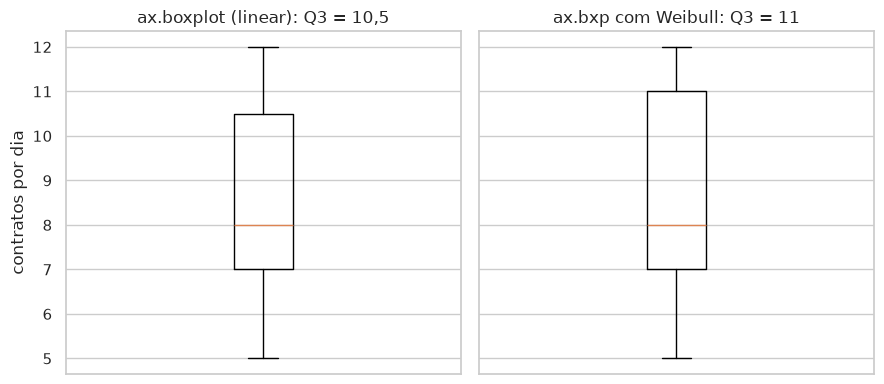

In [10]:
# Executar esta célula

def estatisticas_caixa(dados):
    """Cinco números com os quartis da disciplina, no formato que ax.bxp espera."""
    x = np.asarray(dados)
    caixa = cbook.boxplot_stats(x)[0]
    q1, me, q3 = np.quantile(x, [.25, .5, .75], method="weibull")
    aiq = q3 - q1
    dentro = x[(x >= q1 - 1.5 * aiq) & (x <= q3 + 1.5 * aiq)]
    caixa.update(q1=q1, med=me, q3=q3, whislo=dentro.min(), whishi=dentro.max(),
                 fliers=x[(x < q1 - 1.5 * aiq) | (x > q3 + 1.5 * aiq)])
    return caixa


fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
axs[0].boxplot(contratos)
axs[0].set(title="ax.boxplot (linear): Q3 = 10,5", xticks=[])
axs[1].bxp([estatisticas_caixa(contratos)])
axs[1].set(title="ax.bxp com Weibull: Q3 = 11", xticks=[])
axs[0].set_ylabel("contratos por dia")
fig.tight_layout()
plt.show()

**4.5 Assimetria e curtose.** Os coeficientes da disciplina calculam-se numa linha cada. O SciPy junta os **coeficientes de momentos**, que as soluções oficiais apresentam como complemento (com divisor n, o que o SciPy usa por omissão):
- **assimetria** g₁ = m₃ / m₂^(3/2) (`stats.skew`): referência 0;
- **curtose** β₂ = m₄ / m₂² (`stats.kurtosis(..., fisher=False)`): referência 3 (distribuição normal); menor que 3 → platicúrtica, maior → leptocúrtica. Sem `fisher=False`, o SciPy devolve β₂ − 3.

A função `forma` reúne tudo e é reutilizada nos exercícios 10 e 12.


In [11]:
# Executar esta célula

def forma(dados, mo, q1, me, q3, p10, p90):
    """Coeficientes da disciplina e coeficientes de momentos, lado a lado."""
    m, s = np.mean(dados), np.std(dados, ddof=1)
    return pd.Series({"Pearson Sk1": (m - mo) / s, "Pearson Sk2": 3 * (m - me) / s,
                      "Bowley": (q3 + q1 - 2 * me) / (q3 - q1), "K (ref. 0,263)": (q3 - q1) / (2 * (p90 - p10)),
                      "g1 momentos (ref. 0)": stats.skew(dados),
                      "β2 momentos (ref. 3)": stats.kurtosis(dados, fisher=False)})


f4 = forma(x, mo[0], q1, me, q3, p10, p90)
print(f"4.5 P10 = {p10:g}  P90 = {p90:g}")
print(f4.round(3).to_string())
print("→", classificar(f4["Pearson Sk2"], f4["K (ref. 0,263)"]))
confere("4.5 K", f4["K (ref. 0,263)"], casas=3)

4.5 P10 = 5  P90 = 12
Pearson Sk1             0.709
Pearson Sk2             0.851
Bowley                  0.500
K (ref. 0,263)          0.286
g1 momentos (ref. 0)   -0.063
β2 momentos (ref. 3)    1.777
→ assimetria positiva; platicúrtica
✓ 4.5 K                      obtido 0.286 | oficial 0.286


Repara no g₁ ≈ −0,06: pelos momentos, a distribuição seria quase simétrica, enquanto Pearson diz assimetria positiva (a média 8,67 está acima da mediana 8 e da moda 7). Com 15 valores, os métodos podem divergir; a classificação da disciplina segue Pearson, como a solução oficial explica. A curtose concorda: K > 0,263 e β₂ < 3, ambos platicúrtica.


> **O que mudou em relação ao módulo 1**
>
> - `media`, `mediana` e `desvio_padrao` passaram a métodos do array; `moda` passou a `np.unique(..., return_counts=True)`; o CV passou a `stats.variation(x, ddof=1)`.
> - As funções `quantil`, `quartis` e `outliers` (cerca de 25 linhas) passaram a uma chamada de `np.quantile` e a uma máscara booleana.
> - O diagrama usa os quartis da disciplina graças a `ax.bxp`; com `ax.boxplot` direto, Q₃ seria 10,5.
> - Ganhámos de graça os coeficientes de momentos, que o módulo 1 não calculava.
> - Continuam a ser nossas as funções de interpretação (`interpretar_cv`, `classificar`): os limites são convenções da disciplina.


### Exercício 5 – Alturas dos alunos

**Dados:** 28 alturas, em cm.

**Leitura:** dados contínuos → classes pela regra de Sturges (5 classes de 5 cm). As medidas de 5.5 calculam-se na tabela de classes, como na solução oficial, e confirmam-se com os dados originais.

Aqui as bibliotecas ajudam menos: contam os valores por classe (`np.histogram`), mas **não há função pronta** para quantis ou moda em classes. Escrevemos funções curtas, apoiadas em operações sobre colunas:
- **média:** `np.average(c, weights=n)`, com os pontos médios;
- **quantis:** a ogiva (N em função dos limites) é uma linha poligonal, e `np.interp(p·n, N, limites)` interpola sobre ela. É exatamente Q = L + h·(p·n − N_ant)/nᵢ, aplicada de uma vez;
- **moda:** a fórmula da disciplina, para cada classe modal.

Os limites são arredondados a 10 casas decimais, pela mesma razão do módulo 1 (1,2 + 3 × 0,6 não é exatamente 3,0 no computador).


In [12]:
# Executar esta célula

def tabela_classes(limites, freqs):
    """Tabela de classes [li ; ls[ com ponto médio, n, N, f e F."""
    limites = np.round(np.asarray(limites, dtype=float), 10)
    t = pd.DataFrame({"li": limites[:-1], "ls": limites[1:], "n": np.asarray(freqs)})
    t["c"] = (t["li"] + t["ls"]) / 2
    t["N"] = t["n"].cumsum()
    t["f"] = t["n"] / t["n"].sum()
    t["F"] = t["N"] / t["n"].sum()
    return t[["li", "ls", "c", "n", "N", "f", "F"]]


def classes_de_dados(dados, limites):
    contagens, _ = np.histogram(dados, bins=np.round(limites, 10))
    return tabela_classes(limites, contagens)


def media_classes(t):
    return np.average(t["c"], weights=t["n"])


def variancia_classes(t):
    n = t["n"].sum()
    return np.average((t["c"] - media_classes(t)) ** 2, weights=t["n"]) * n / (n - 1)


def quantil_classes(t, p):
    """Interpolação na ogiva: Q = L + h·(p·n − N_ant)/n_classe."""
    N = np.concatenate([[0], t["N"]])
    limites = np.concatenate([t["li"].iloc[:1], t["ls"]])
    return float(np.interp(p * t["n"].sum(), N, limites))


def moda_classes(t):
    """Mo = L + h·n_seg/(n_ant + n_seg), para cada classe modal."""
    n = np.concatenate([[0], t["n"], [0]])          # zeros nas pontas: vizinhos inexistentes
    modas = []
    for i in np.flatnonzero(t["n"].to_numpy() == t["n"].max()):
        h = t["ls"].iloc[i] - t["li"].iloc[i]
        modas.append(float(t["li"].iloc[i] + h * n[i + 2] / (n[i] + n[i + 2])))
    return modas


a = np.array(alturas)
k = sturges(len(a))
limites5 = 150 + 5 * np.arange(k + 1)
t5 = classes_de_dados(a, limites5)
print(f"5.1 Sturges: k = 1 + 3,3·log10({len(a)}) ≈ {1 + 3.3 * math.log10(len(a)):.2f} → {k} classes de 5 cm")
display(t5)

5.1 Sturges: k = 1 + 3,3·log10(28) ≈ 5.78 → 5 classes de 5 cm


,li,ls,c,n,N,f,F
0,150.0,155.0,152.5,3,3,0.1071,0.1071
1,155.0,160.0,157.5,5,8,0.1786,0.2857
2,160.0,165.0,162.5,7,15,0.2500,0.5357
3,165.0,170.0,167.5,7,22,0.2500,0.7857
4,170.0,175.0,172.5,6,28,0.2143,1.0000


**5.2 Histograma.** `sns.histplot` aceita os limites das classes em `bins` e `stat="percent"` para usar fᵢ em %; por cima, o polígono de frequências, fechado no eixo como na resolução oficial. À direita, o histograma com `bins="sturges"` do NumPy: a escolha das classes muda a forma que vemos.


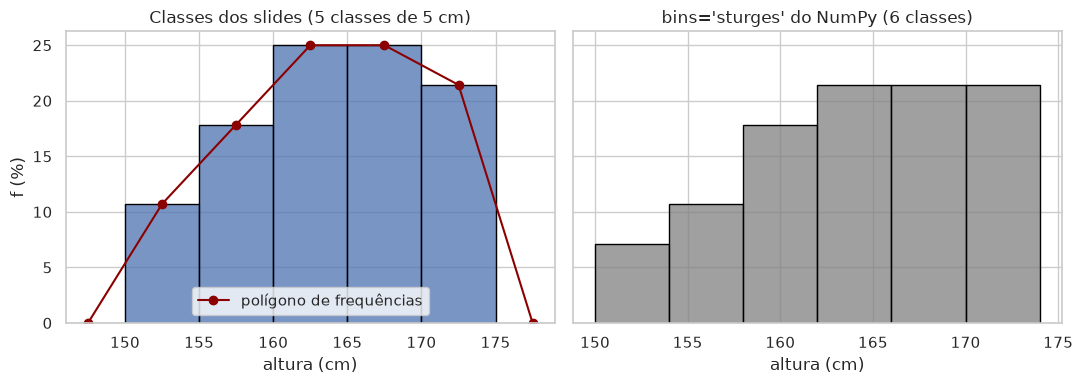

In [13]:
# Executar esta célula

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.histplot(a, bins=limites5, stat="percent", ax=axs[0], edgecolor="black")
centros = np.concatenate([[limites5[0] - 2.5], t5["c"], [limites5[-1] + 2.5]])
axs[0].plot(centros, np.concatenate([[0], 100 * t5["f"], [0]]), "o-", color="darkred",
            label="polígono de frequências")
axs[0].set(title="Classes dos slides (5 classes de 5 cm)", xlabel="altura (cm)", ylabel="f (%)")
axs[0].legend(loc="lower center")
sns.histplot(a, bins="sturges", stat="percent", ax=axs[1], edgecolor="black", color="gray")
axs[1].set(title="bins='sturges' do NumPy (6 classes)", xlabel="altura (cm)")
fig.tight_layout()
plt.show()

In [14]:
# Executar esta célula

modais = t5.loc[t5["n"] == t5["n"].max()]
print("5.3 classe(s) de maior efetivo:", ", ".join(f"[{li:g}; {ls:g}[" for li, ls in zip(modais["li"], modais["ls"])))
print(f"5.4 pelo menos 1,65 m: {(a >= 165).sum()}/{len(a)} = {100 * (a >= 165).mean():.2f} %")

print("5.5 com a tabela de classes (solução oficial):")
modas5 = moda_classes(t5)
print(f"    média = {media_classes(t5):.2f}  mediana = {quantil_classes(t5, .5):.2f}  modas = {[round(x, 2) for x in modas5]}")
confere("5.5 média (classes)", media_classes(t5))
confere("5.5 mediana (classes)", quantil_classes(t5, .5))
confere("5.5 1.ª moda (classes)", modas5[0])
confere("5.5 2.ª moda (classes)", modas5[1])
confere("5.5 Q1 (classes)", quantil_classes(t5, .25))
confere("5.5 Q3 (classes)", quantil_classes(t5, .75))
valores, contagens = np.unique(a, return_counts=True)
cv5 = 100 * stats.variation(a, ddof=1)
print(f"    dados originais: média = {a.mean():.2f}  Me = {np.median(a)}  modas = {valores[contagens == contagens.max()].tolist()}"
      f"  s² = {a.var(ddof=1):.2f}  CV = {cv5:.2f} % → {interpretar_cv(cv5)}")
confere("5.5 s", a.std(ddof=1))
print(f"    amplitude total = {np.ptp(a)} cm")

5.3 classe(s) de maior efetivo: [160; 165[, [165; 170[
5.4 pelo menos 1,65 m: 13/28 = 46.43 %
5.5 com a tabela de classes (solução oficial):
    média = 163.93  mediana = 164.29  modas = [162.92, 167.31]
✓ 5.5 média (classes)        obtido 163.93 | oficial 163.93
✓ 5.5 mediana (classes)      obtido 164.29 | oficial 164.29
✓ 5.5 1.ª moda (classes)     obtido 162.92 | oficial 162.92
✓ 5.5 2.ª moda (classes)     obtido 167.31 | oficial 167.31
✓ 5.5 Q1 (classes)           obtido 159.00 | oficial 159.00
✓ 5.5 Q3 (classes)           obtido 169.29 | oficial 169.29
    dados originais: média = 163.32  Me = 164.0  modas = [158, 166]  s² = 40.89  CV = 3.92 % → dispersão baixa
✓ 5.5 s                      obtido 6.39 | oficial 6.39
    amplitude total = 24 cm


> **O que mudou em relação ao módulo 1**
>
> - Contar por classe passou a uma chamada: `np.histogram(dados, bins=limites)`, que já fecha a última classe como a disciplina.
> - O histograma com polígono passou a `sns.histplot` e uma linha de `ax.plot`.
> - **Sem função pronta:** os quantis e a moda em classes continuam a ser código nosso. A diferença é que os quantis ficaram numa linha, graças a `np.interp` sobre a ogiva, em vez de um ciclo à procura da classe.
> - **Cuidado:** `bins="sturges"` do NumPy daria 6 classes em vez das 5 dos slides.


### Exercício 6 – Satisfação dos alunos

**Dados:** notas médias de satisfação (1 a 5) de 35 alunos.

**Leitura:** Sturges → 6 classes de 0,6 a partir de 1,2; classe modal e classe mediana; média e s com dados agrupados e não agrupados; quartis e diagrama com os dados originais. Reutilizamos as funções do exercício 5.


6.1 Sturges → 6 classes de amplitude 0,6 a partir de 1,2


,li,ls,c,n,N,f,F
0,1.2,1.8,1.5,1,1,0.0286,0.0286
1,1.8,2.4,2.1,9,10,0.2571,0.2857
2,2.4,3.0,2.7,5,15,0.1429,0.4286
3,3.0,3.6,3.3,8,23,0.2286,0.6571
4,3.6,4.2,3.9,10,33,0.2857,0.9429
5,4.2,4.8,4.5,2,35,0.0571,1.0000


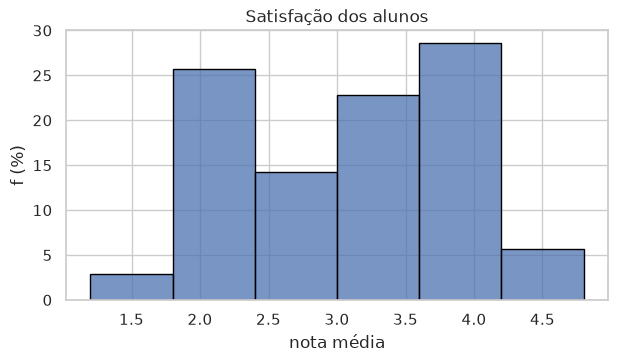

6.3 classe modal: [3.6; 4.2[ | classe mediana: [3.0; 3.6[
6.4 não agrupados: média = 3.057  s = 0.857 | agrupados: média = 3.094  s = 0.822
    Agrupar substitui cada valor pelo ponto médio da classe: perde-se precisão, por isso os dados originais prevalecem.
✓ 6.4 média (agrupados)      obtido 3.094 | oficial 3.094
6.5 mediana = 3.1  moda = [2.2]  Q1 = 2.3  Q3 = 3.8
6.6 mín = 1.2  Q1 = 2.3  Me = 3.1  Q3 = 3.8  máx = 4.5  outliers: nenhum


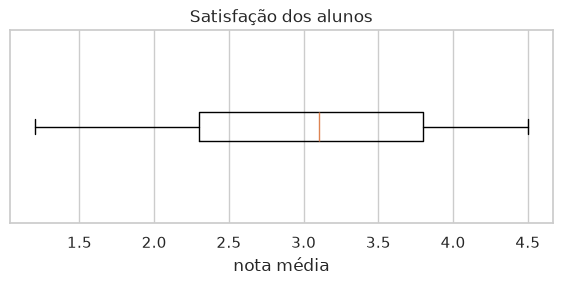

In [15]:
# Executar esta célula

nt = np.array(notas)
t6 = classes_de_dados(nt, 1.2 + 0.6 * np.arange(sturges(len(nt)) + 1))
print(f"6.1 Sturges → {sturges(len(nt))} classes de amplitude 0,6 a partir de 1,2")
display(t6)

fig, ax = plt.subplots(figsize=(7, 3.5))                       # 6.2
limites6 = np.concatenate([t6["li"].iloc[:1], t6["ls"]])
sns.histplot(nt, bins=limites6, stat="percent", ax=ax, edgecolor="black")
ax.set(title="Satisfação dos alunos", xlabel="nota média", ylabel="f (%)")
plt.show()

modal = t6.loc[t6["n"] == t6["n"].max()].iloc[0]
mediana_cl = t6.loc[t6["F"] >= 0.5].iloc[0]
print(f"6.3 classe modal: [{modal['li']}; {modal['ls']}[ | classe mediana: [{mediana_cl['li']}; {mediana_cl['ls']}[")
print(f"6.4 não agrupados: média = {nt.mean():.3f}  s = {nt.std(ddof=1):.3f} | "
      f"agrupados: média = {media_classes(t6):.3f}  s = {math.sqrt(variancia_classes(t6)):.3f}")
print("    Agrupar substitui cada valor pelo ponto médio da classe: perde-se precisão, por isso os dados originais prevalecem.")
confere("6.4 média (agrupados)", media_classes(t6), casas=3)

q1, me, q3 = np.quantile(nt, [.25, .5, .75], method="weibull")
valores, contagens = np.unique(nt, return_counts=True)
print(f"6.5 mediana = {me:g}  moda = {valores[contagens == contagens.max()].tolist()}  Q1 = {q1:g}  Q3 = {q3:g}")
caixa = estatisticas_caixa(nt)
print(f"6.6 mín = {nt.min()}  Q1 = {q1:g}  Me = {me:g}  Q3 = {q3:g}  máx = {nt.max()}  "
      f"outliers: {caixa['fliers'].tolist() or 'nenhum'}")
fig, ax = plt.subplots(figsize=(7, 2.5))
try:
    ax.bxp([caixa], orientation="horizontal")   # matplotlib 3.10 ou superior
except TypeError:
    ax.bxp([caixa], vert=False)                 # versões anteriores
ax.set(title="Satisfação dos alunos", xlabel="nota média", yticks=[])
plt.show()

> **O que mudou em relação ao módulo 1**
>
> - As funções do ex. 5 servem sem alterações: só mudam os limites.
> - A média e o desvio-padrão agrupados são `np.average` com pesos, a mesma ideia da média ponderada.
> - O diagrama horizontal reutiliza `estatisticas_caixa` do ex. 4. O `try`/`except` escolhe o parâmetro certo conforme a versão do matplotlib (`orientation` nas versões recentes, `vert` nas anteriores).


### Exercício 7 – Q.I. de 80 crianças

**Dados:** 80 coeficientes de inteligência.

**Leitura:** Sturges → 7 classes de amplitude 11 a partir de 56. É aqui que `pd.cut` falharia (secção 2.3): os dois Q.I. iguais a 133 ficariam sem classe. Com `np.histogram` a tabela fica certa. A média pedida é a dos dados originais.


In [16]:
# Executar esta célula

q = np.array(qi)
k = sturges(len(q))
h = np.ptp(q) / k                                          # (133 − 56)/7 = 11
t7 = classes_de_dados(q, q.min() + h * np.arange(k + 1))
print(f"7.1 Sturges → {k} classes de amplitude {h:g} a partir de {q.min()}")
display(t7)
print(f"7.2 Q.I. médio (dados originais) = {q.mean():.3f} | estimativa pelos pontos médios = {media_classes(t7):.2f}")
confere("7.2 média", q.mean(), casas=3)

7.1 Sturges → 7 classes de amplitude 11 a partir de 56


,li,ls,c,n,N,f,F
0,56.0,67.0,61.5,1,1,0.0125,0.0125
1,67.0,78.0,72.5,4,5,0.0500,0.0625
2,78.0,89.0,83.5,13,18,0.1625,0.2250
3,89.0,100.0,94.5,21,39,0.2625,0.4875
4,100.0,111.0,105.5,27,66,0.3375,0.8250
5,111.0,122.0,116.5,10,76,0.1250,0.9500
6,122.0,133.0,127.5,4,80,0.0500,1.0000


7.2 Q.I. médio (dados originais) = 98.825 | estimativa pelos pontos médios = 99.31
✓ 7.2 média                  obtido 98.825 | oficial 98.825


**Complemento: distribuição empírica e ogiva.** `sns.ecdfplot` desenha a **função de distribuição empírica**: para cada valor x, a proporção de crianças com Q.I. menor ou igual a x. É a versão «em escada» da coluna F, sem agrupar. Por cima, a ogiva das 7 classes: agrupar suaviza os degraus.


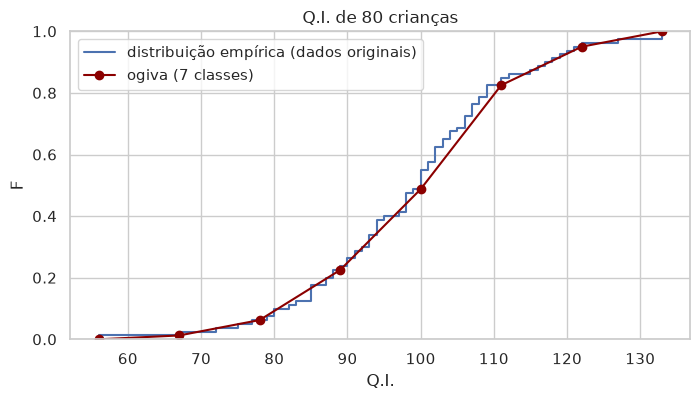

In [17]:
# Executar esta célula

fig, ax = plt.subplots(figsize=(8, 4))
sns.ecdfplot(q, ax=ax, label="distribuição empírica (dados originais)")
ax.plot(np.concatenate([t7["li"].iloc[:1], t7["ls"]]), np.concatenate([[0], t7["F"]]), "o-",
        color="darkred", label="ogiva (7 classes)")
ax.set(title="Q.I. de 80 crianças", xlabel="Q.I.", ylabel="F")
ax.legend()
plt.show()

> **O que mudou em relação ao módulo 1**
>
> - `max(qi) − min(qi)` passou a `np.ptp(q)` (*peak to peak*, amplitude total).
> - **Cuidado:** este é o exercício em que `pd.cut(..., right=False)` deixaria dois valores de fora. `np.histogram` resolve-o sem código extra.
> - Ganhámos a função de distribuição empírica (`sns.ecdfplot`), que mostra a coluna F sem perder informação com o agrupamento.


### Exercício 8 – Prova de tiro

**Dados:** tiros certos (em 10) de 13 concorrentes.

**Leitura:** quantis pela posição (n + 1)/4: `np.quantile(..., method="weibull")` ou `statistics.quantiles` dão os valores dos slides. Para 8.2, máscaras booleanas contam quantos o atirador supera.


In [18]:
# Executar esta célula

t = np.sort(tiros)
n = len(t)
q1, me, q3 = np.quantile(t, [.25, .5, .75], method="weibull")
print(f"8.1 ordenados: {t.tolist()}")
print(f"    posições: Me = {(n + 1) / 2}  Q1 = {(n + 1) / 4}  Q3 = {3 * (n + 1) / 4}")
print(f"    mediana = {me:g}  Q1 = {q1:g}  Q3 = {q3:g}  | statistics.quantiles: {statistics.quantiles(tiros, n=4)}")
confere("8.1 Q1", q1)
confere("8.1 mediana", me)
confere("8.1 Q3", q3)
print(f"8.2 Com 8 tiros: acima da mediana ({me:g}) e perto de Q3 ({q3:g}); "
      f"supera {(t < 8).sum()} dos {n} concorrentes e só {(t > 8).sum()} fizeram melhor → bom atirador")
print("\nOs outros métodos dariam Q3 diferente:")
comparar_quartis(tiros)

8.1 ordenados: [2, 5, 5, 5, 6, 7, 7, 8, 8, 8, 9, 10, 10]
    posições: Me = 7.0  Q1 = 3.5  Q3 = 10.5
    mediana = 7  Q1 = 5  Q3 = 8.5  | statistics.quantiles: [5.0, 7.0, 8.5]
✓ 8.1 Q1                     obtido 5.00 | oficial 5.00
✓ 8.1 mediana                obtido 7.00 | oficial 7.00
✓ 8.1 Q3                     obtido 8.50 | oficial 8.50
8.2 Com 8 tiros: acima da mediana (7) e perto de Q3 (8.5); supera 7 dos 13 concorrentes e só 3 fizeram melhor → bom atirador

Os outros métodos dariam Q3 diferente:


,Q1,Me,Q3
slides · statistics.quantiles,5.0,7.0,8.500
NumPy method='weibull',5.0,7.0,8.500
NumPy por omissão (linear),5.0,7.0,8.000
pandas .quantile(),5.0,7.0,8.000
statistics method='inclusive',5.0,7.0,8.000
NumPy method='hazen',5.0,7.0,8.250
NumPy method='median_unbiased',5.0,7.0,8.333


> **O que mudou em relação ao módulo 1**
>
> - O quantil por posição com interpolação, escrito à mão no módulo 1, é uma opção de `np.quantile`: `method="weibull"`.
> - **Cuidado:** sem essa opção, o NumPy e o pandas dariam Q₃ = 8 em vez de 8,5 (ver a tabela). A pergunta 8.2 mudaria de resposta? Aqui não, mas noutros dados poderia.


### Exercício 9 – Horas de instrução

**Dados:** tabela horas / n.º de alunos (n = 50).

**Leitura:** quando o enunciado dá uma tabela valor/n.º, há duas formas de trabalhar:
- **ponderar:** `np.average(valores, weights=freqs)` dá a média sem expandir os dados;
- **expandir:** `np.repeat(valores, freqs)` reconstrói a lista completa (50 valores) e permite usar qualquer função, incluindo os quantis.


In [19]:
# Executar esta célula

h, n_h = np.array(horas), np.array(alunos)
dados9 = np.repeat(h, n_h)                      # 3 vezes 12, 6 vezes 13, ...
display(tabela_freq(dados9, "horas"))

m9 = np.average(h, weights=n_h)
print(f"9.1 média = {(h * n_h).sum()}/{n_h.sum()} = {m9:.2f} → cerca de 15 a 16 horas")
confere("9.1 média", m9)

q1, me, q3 = np.quantile(dados9, [.25, .5, .75], method="weibull")
print(f"9.2 posições: Me {(n_h.sum() + 1) / 2}  Q1 {(n_h.sum() + 1) / 4}  Q3 {3 * (n_h.sum() + 1) / 4}")
print(f"    mediana = {me:g}  Q1 = {q1:g}  Q3 = {q3:g}")
confere("9.2 Q1", q1)
confere("9.2 mediana", me)
confere("9.2 Q3", q3)
print(f"9.3 moda = {h[n_h == n_h.max()].tolist()} horas (maior n = {n_h.max()})")

,n,N,f,F
horas,,,,
12,3,3,0.06,0.06
13,6,9,0.12,0.18
14,8,17,0.16,0.34
15,10,27,0.20,0.54
16,7,34,0.14,0.68
17,6,40,0.12,0.80
18,5,45,0.10,0.90
19,3,48,0.06,0.96
20,2,50,0.04,1.00


9.1 média = 777/50 = 15.54 → cerca de 15 a 16 horas
✓ 9.1 média                  obtido 15.54 | oficial 15.54
9.2 posições: Me 25.5  Q1 12.75  Q3 38.25
    mediana = 15  Q1 = 14  Q3 = 17
✓ 9.2 Q1                     obtido 14.00 | oficial 14.00
✓ 9.2 mediana                obtido 15.00 | oficial 15.00
✓ 9.2 Q3                     obtido 17.00 | oficial 17.00
9.3 moda = [15] horas (maior n = 10)


> **O que mudou em relação ao módulo 1**
>
> - `media_ponderada` passou a `np.average(..., weights=...)`.
> - `quantil_tabela` e `valor_na_posicao`, que liam a coluna N, deixaram de ser precisas: com `np.repeat` os dados ficam expandidos e usa-se o mesmo `np.quantile` dos dados individuais.
> - A moda é uma máscara: `h[n_h == n_h.max()]`.
> - Expandir só é razoável com tabelas pequenas ou médias (aqui 50 valores; no ex. 10, 1000). Com milhões de observações, prefere-se trabalhar com os pesos.


### Exercício 10 – Ocupantes por veículo

**Dados:** tabela de 1 a 4 ocupantes / n.º de veículos (n = 1000).

**Leitura:** sequência completa numa tabela valor/n.º: expandimos com `np.repeat` e usamos as mesmas ferramentas do ex. 4, incluindo a função `forma`.


In [20]:
# Executar esta célula

dados10 = np.repeat(ocupantes, veiculos)
t10 = tabela_freq(dados10, "ocupantes")
print("10.1 Variável: n.º de ocupantes por veículo — quantitativa discreta; unidade: veículo")
display(t10)
print("10.2 2 ou menos:", t10.loc[2, "N"], "veículos")
print(f"10.3 entre 3 e 4 inclusive: {100 * ((dados10 >= 3) & (dados10 <= 4)).mean():.1f} %")

valores, contagens = np.unique(dados10, return_counts=True)
mo = valores[contagens == contagens.max()]
m, me = dados10.mean(), np.median(dados10)
print(f"10.4 moda = {mo.tolist()}   10.5 mediana = {me:g}   10.6 média = {m:g}")
confere("10.6 média", m)

ordens = {"Q1": .25, "Q3": .75, "D2": .2, "D7": .7, "P35": .35, "P60": .6, "P85": .85}
qs = dict(zip(ordens, np.quantile(dados10, list(ordens.values()), method="weibull").tolist()))
print("10.7 a 10.9", {nome: f"{v:g}" for nome, v in qs.items()})

p10, p90 = np.quantile(dados10, [.1, .9], method="weibull")
f10 = forma(dados10, mo[0], qs["Q1"], me, qs["Q3"], p10, p90)
print(f"10.10 s = {dados10.std(ddof=1):.4f}")
print(f10.round(3).to_string())
print("→", classificar(f10["Pearson Sk2"], f10["K (ref. 0,263)"]))
confere("10.10 K", f10["K (ref. 0,263)"], casas=3)

aiq = qs["Q3"] - qs["Q1"]
fora = dados10[(dados10 < qs["Q1"] - 1.5 * aiq) | (dados10 > qs["Q3"] + 1.5 * aiq)]
print(f"10.11 limites moderados [{qs['Q1'] - 1.5 * aiq:g}; {qs['Q3'] + 1.5 * aiq:g}], "
      f"severos [{qs['Q1'] - 3 * aiq:g}; {qs['Q3'] + 3 * aiq:g}] → outliers: {fora.tolist() or 'nenhum'}")

10.1 Variável: n.º de ocupantes por veículo — quantitativa discreta; unidade: veículo


,n,N,f,F
ocupantes,,,,
1,150,150,0.150,0.150
2,275,425,0.275,0.425
3,320,745,0.320,0.745
4,255,1000,0.255,1.000


10.2 2 ou menos: 425 veículos
10.3 entre 3 e 4 inclusive: 57.5 %
10.4 moda = [3]   10.5 mediana = 3   10.6 média = 2.68
✓ 10.6 média                 obtido 2.68 | oficial 2.68
10.7 a 10.9 {'Q1': '2', 'Q3': '4', 'D2': '2', 'D7': '3', 'P35': '2', 'P60': '3', 'P85': '4'}
10.10 s = 1.0142
Pearson Sk1            -0.316
Pearson Sk2            -0.947
Bowley                  0.000
K (ref. 0,263)          0.333
g1 momentos (ref. 0)   -0.193
β2 momentos (ref. 3)    1.924
→ assimetria negativa; platicúrtica
✓ 10.10 K                    obtido 0.333 | oficial 0.333
10.11 limites moderados [-1; 7], severos [-4; 10] → outliers: nenhum


O Bowley dá 0 porque, em dados discretos, os quartis coincidem com valores inteiros; Pearson e g₁ ≈ −0,19 concordam numa assimetria negativa. K > 0,263 e β₂ ≈ 1,92 < 3: platicúrtica. São os valores de g₁ e β₂ que a solução oficial apresenta como complemento.


> **O que mudou em relação ao módulo 1**
>
> - Os sete quantis de 10.7 a 10.9 saem de uma só chamada a `np.quantile`, com uma lista de ordens.
> - 10.2 lê-se diretamente na tabela pelo valor: `t10.loc[2, "N"]`.
> - «Entre 3 e 4 inclusive» passou a uma máscara com `&`, cada condição entre parênteses.
> - A função `forma` do ex. 4 serviu sem alterações e trouxe os coeficientes de momentos.


### Exercício 11 – Composição de iogurtes

**Dados:** 7 iogurtes naturais e 13 normais e de frutas; proteínas, lípidos e hidratos de carbono (g).

**Leitura:** em vez de dois dicionários e ciclos, junta-se tudo num único DataFrame em **formato longo**: uma linha por iogurte, uma coluna por variável e uma coluna com o grupo. Depois, `groupby("grupo").agg(...)` calcula as medidas para todos os grupos e variáveis de uma vez; podes passar a `agg` funções tuas, como o coeficiente de variação.


In [21]:
# Executar esta célula

iogurtes = pd.concat([pd.DataFrame(naturais).assign(grupo="naturais"),
                      pd.DataFrame(normais).assign(grupo="normais e frutas")], ignore_index=True)
print(iogurtes.shape, "→ uma linha por iogurte")
display(iogurtes.head(3))

p = iogurtes["proteinas"]
print(f"11.1 proteínas (n = {len(p)}): média = {p.mean():.2f} g  s (n − 1) = {p.std():.3f} g  σ (n) = {p.std(ddof=0):.3f} g")
confere("11.1 σ (divisor n)", p.std(ddof=0), casas=3)

(20, 4) → uma linha por iogurte


,proteinas,lipidos,hidratos,grupo
0,6.6,0.5,8.4,naturais
1,5.4,0.5,5.9,naturais
2,5.4,3.7,15.6,naturais


11.1 proteínas (n = 20): média = 4.77 g  s (n − 1) = 1.012 g  σ (n) = 0.986 g
✓ 11.1 σ (divisor n)         obtido 0.986 | oficial 0.986


Em 11.1, a solução oficial usa divisor n (σ = 0,986); com o divisor n − 1 dos slides obtém-se 1,012. No pandas, `std()` usa n − 1 e `std(ddof=0)` usa n.


In [22]:
# Executar esta célula

def cv(serie):
    return 100 * serie.std() / serie.mean()


resumo = iogurtes.groupby("grupo")[["hidratos", "lipidos"]].agg(["count", "mean", "std", cv])
print("11.2 comparação por grupo (média, s, CV)")
display(resumo.round(2))
medias = iogurtes.groupby("grupo")[["hidratos", "lipidos"]].mean()
confere("11.2 hidratos naturais", medias.loc["naturais", "hidratos"])
confere("11.2 hidratos normais", medias.loc["normais e frutas", "hidratos"])
confere("11.2 lípidos naturais", medias.loc["naturais", "lipidos"])
confere("11.2 lípidos normais", medias.loc["normais e frutas", "lipidos"])

11.2 comparação por grupo (média, s, CV)


hidratos                     lipidos                    
                    count   mean   std     cv   count  mean   std      cv
grupo                                                                    
naturais                7   8.30  3.68  44.37       7  1.29  1.31  101.85
normais e frutas       13  14.17  4.61  32.57      13  3.23  2.68   83.10

✓ 11.2 hidratos naturais     obtido 8.30 | oficial 8.30
✓ 11.2 hidratos normais      obtido 14.17 | oficial 14.17
✓ 11.2 lípidos naturais      obtido 1.29 | oficial 1.29
✓ 11.2 lípidos normais       obtido 3.23 | oficial 3.23


**11.3 Dispersão e outliers dos lípidos.** Pelo desvio-padrão, a maior dispersão absoluta é a dos normais e frutas (2,68 contra 1,31 g); pelo CV, em termos relativos, é a dos naturais (101,8 % contra 83,1 %). Diz sempre que critério usas.

Para os outliers, o critério da disciplina usa os quartis. Uma alternativa comum é o **valor padronizado** z = (x − x̄)/s (`stats.zscore`), que mede a distância à média em desvios-padrão; costuma considerar-se outlier |z| > 3. O problema: o próprio outlier puxa a média e aumenta s, e pode «esconder-se». O critério dos quartis é **robusto**, porque Q₁ e Q₃ quase não mudam com um valor extremo.


,lípidos,z,"fora de 1,5·AIQ",fora de 3·AIQ
7,11.5,3.08,True,True
3,4.1,0.32,False,False
12,3.8,0.21,False,False


Q1 = 1.75, Q3 = 3.65, AIQ = 1.90: 11,5 é outlier severo pelo critério dos quartis.
z de 11,5 = 3.08: fica pouco acima de 3, porque o próprio 11,5 aumenta a média e o desvio-padrão.


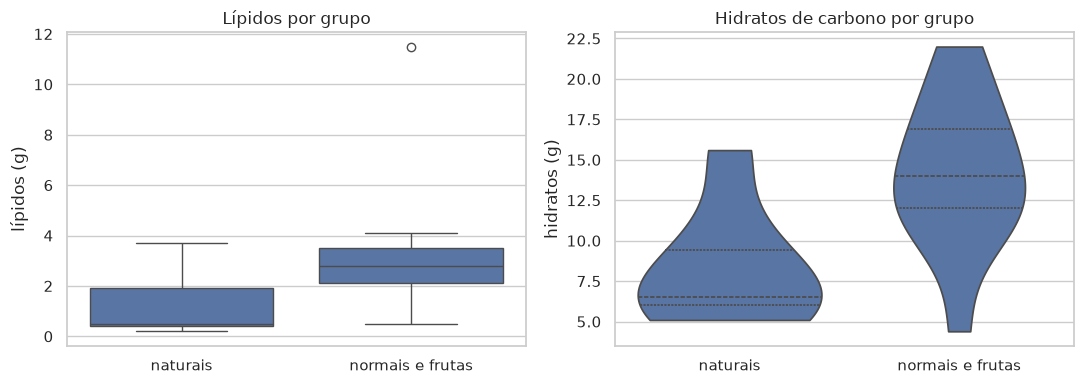

In [23]:
# Executar esta célula

lip = iogurtes.loc[iogurtes["grupo"] == "normais e frutas", "lipidos"].to_numpy()
q1, q3 = np.quantile(lip, [.25, .75], method="weibull")
aiq = q3 - q1
z = stats.zscore(lip, ddof=1)
display(pd.DataFrame({"lípidos": lip, "z": z.round(2),
                      "fora de 1,5·AIQ": (lip < q1 - 1.5 * aiq) | (lip > q3 + 1.5 * aiq),
                      "fora de 3·AIQ": (lip < q1 - 3 * aiq) | (lip > q3 + 3 * aiq)})
        .sort_values("lípidos", ascending=False).head(3))
print(f"Q1 = {q1:g}, Q3 = {q3:g}, AIQ = {aiq:.2f}: 11,5 é outlier severo pelo critério dos quartis.")
print(f"z de 11,5 = {z.max():.2f}: fica pouco acima de 3, porque o próprio 11,5 aumenta a média e o desvio-padrão.")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=iogurtes, x="grupo", y="lipidos", ax=axs[0])
axs[0].set(title="Lípidos por grupo", xlabel="", ylabel="lípidos (g)")
sns.violinplot(data=iogurtes, x="grupo", y="hidratos", ax=axs[1], inner="quart", cut=0)
axs[1].set(title="Hidratos de carbono por grupo", xlabel="", ylabel="hidratos (g)")
fig.tight_layout()
plt.show()

Com os dados em formato longo, o seaborn compara grupos numa só chamada: `x` é o grupo e `y` a variável. O diagrama de violino junta à caixa a forma da distribuição. Lembra-te de que os quartis destes gráficos usam o método linear (secção 2.2).


> **O que mudou em relação ao módulo 1**
>
> - Os dois ciclos `for` sobre variáveis e grupos passaram a uma só linha: `groupby("grupo").agg([...])`, que devolve a tabela de comparação completa.
> - O formato longo (uma linha por observação) é o formato que o pandas e o seaborn esperam: o mesmo DataFrame serve para os cálculos e para os gráficos.
> - Ganhámos os valores padronizados (`stats.zscore`) e os gráficos por grupo, que o módulo 1 não tinha.


### Exercício 12 – Salários

**Dados:** 600 colaboradores em 7 classes de 250 €.

**Leitura:** classes dadas → `tabela_classes` e as funções do ex. 5; as percentagens «até um limite» leem-se na coluna F com uma máscara sobre `ls`. Para a forma da distribuição, os momentos calculam-se com os pontos médios repetidos pelas frequências (`np.repeat`), como na solução oficial.

**Atenção a 12.6 e 12.7:** com classes [a ; b[, «até 1000 €» e «no máximo 750 €» incluem o próprio limite, mas a tabela não diz quantos salários são exatamente iguais a esses valores. A resposta usual é uma aproximação que trata o limite como se pertencesse à classe anterior.


In [24]:
# Executar esta célula

t12 = tabela_classes(limites12, freqs12)
print("12.1 Tabela completa")
display(t12)

12.1 Tabela completa


,li,ls,c,n,N,f,F
0,250.0,500.0,375.0,60,60,0.1000,0.1000
1,500.0,750.0,625.0,150,210,0.2500,0.3500
2,750.0,1000.0,875.0,230,440,0.3833,0.7333
3,1000.0,1250.0,1125.0,70,510,0.1167,0.8500
4,1250.0,1500.0,1375.0,43,553,0.0717,0.9217
5,1500.0,1750.0,1625.0,32,585,0.0533,0.9750
6,1750.0,2000.0,1875.0,15,600,0.0250,1.0000


**12.2 Histograma e ogiva.** Sem os dados originais, `ax.hist` desenha o histograma a partir dos pontos médios com `weights`: cada ponto médio «pesa» a frequência da sua classe. A ogiva liga os pontos (limite, F): é a linha sobre a qual `quantil_classes` interpola. Para encontrar um quartil, sobe-se até F = 0,25, 0,5 ou 0,75 e lê-se o salário correspondente.


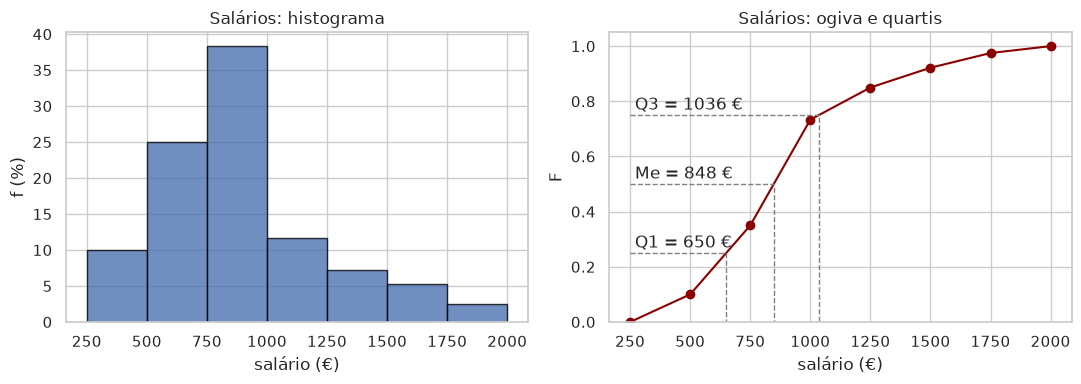

In [25]:
# Executar esta célula

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(t12["c"], bins=limites12, weights=100 * t12["f"], edgecolor="black", alpha=0.8)
axs[0].set(title="Salários: histograma", xlabel="salário (€)", ylabel="f (%)")

axs[1].plot(limites12, np.concatenate([[0], t12["F"]]), "o-", color="darkred")
for prob, nome in ((.25, "Q1"), (.5, "Me"), (.75, "Q3")):
    valor = quantil_classes(t12, prob)
    axs[1].plot([limites12[0], valor, valor], [prob, prob, 0], "--", color="gray", linewidth=1)
    axs[1].text(limites12[0] + 20, prob + 0.02, f"{nome} = {valor:.0f} €")
axs[1].set(title="Salários: ogiva e quartis", xlabel="salário (€)", ylabel="F", ylim=(0, 1.05))
fig.tight_layout()
plt.show()

In [26]:
# Executar esta célula

def F_ate(limite):
    """Frequência relativa das classes que terminam até `limite`."""
    return t12.loc[t12["ls"] <= limite, "f"].sum()


print(f"12.3 no mínimo 1000 €: {100 * (1 - F_ate(1000)):.1f} %")
print(f"12.4 pelo menos 750 €: {100 * (1 - F_ate(750)):.1f} %")
print(f"12.5 entre 1250 e 1750 €: {100 * (F_ate(1750) - F_ate(1250)):.1f} %")
print(f"12.6 no máximo 750 €: {100 * F_ate(750):.1f} % (aproximação: ver nota acima)")
print(f"12.7 até 1000 €: {t12.loc[t12['ls'] <= 1000, 'n'].sum()} colaboradores (idem)")

m12, me12, mo12 = media_classes(t12), quantil_classes(t12, .5), moda_classes(t12)[0]
cmod = t12.loc[t12["n"].idxmax()]
print(f"12.8 média = {m12:.2f}  mediana = {me12:.2f}  moda = {mo12:.2f}  classe modal = [{cmod['li']:g}; {cmod['ls']:g}[")
confere("12.8 média", m12)
confere("12.8 mediana", me12)
confere("12.8 moda", mo12)

s2 = variancia_classes(t12)
s12 = math.sqrt(s2)
cv12 = 100 * s12 / m12
print(f"12.9 s² = {s2:.2f}  s = {s12:.2f}  CV = {cv12:.2f} % → {interpretar_cv(cv12)}")
confere("12.9 s", s12)
confere("12.9 CV (%)", cv12)

q = {nome: quantil_classes(t12, prob) for nome, prob in
     (("Q1", .25), ("Q3", .75), ("D2", .2), ("D4", .4), ("P10", .1), ("P90", .9))}
print("12.10", {nome: round(v, 2) for nome, v in q.items()})

dados12 = np.repeat(t12["c"], t12["n"])                       # pontos médios repetidos
f12 = forma(dados12, mo12, q["Q1"], me12, q["Q3"], q["P10"], q["P90"])
print("12.11")
print(f12.round(3).to_string())
print("→", classificar(f12["Pearson Sk2"], f12["K (ref. 0,263)"]))

12.3 no mínimo 1000 €: 26.7 %
12.4 pelo menos 750 €: 65.0 %
12.5 entre 1250 e 1750 €: 12.5 %
12.6 no máximo 750 €: 35.0 % (aproximação: ver nota acima)
12.7 até 1000 €: 440 colaboradores (idem)
12.8 média = 892.50  mediana = 847.83  moda = 829.55  classe modal = [750; 1000[
✓ 12.8 média                 obtido 892.50 | oficial 892.50
✓ 12.8 mediana               obtido 847.83 | oficial 847.83
✓ 12.8 moda                  obtido 829.55 | oficial 829.55
12.9 s² = 120728.30  s = 347.46  CV = 38.93 % → dispersão elevada
✓ 12.9 s                     obtido 347.46 | oficial 347.46
✓ 12.9 CV (%)                obtido 38.93 | oficial 38.93
12.10 {'Q1': 650.0, 'Q3': 1035.71, 'D2': 600.0, 'D4': 782.61, 'P10': 500.0, 'P90': 1424.42}
12.11
Pearson Sk1             0.181
Pearson Sk2             0.386
Bowley                 -0.026
K (ref. 0,263)          0.209
g1 momentos (ref. 0)    0.849
β2 momentos (ref. 3)    3.533
→ assimetria positiva; leptocúrtica


Pearson e g₁ ≈ 0,85 concordam (assimetria positiva); o Bowley é quase nulo porque só olha para o centro. K < 0,263 e β₂ ≈ 3,53 > 3: leptocúrtica.

**12.12 Outliers em classes.** Os limites calculam-se com os quartis interpolados. Com dados em classes não se conhecem os valores individuais, por isso só se pode dizer quantos salários estão *certamente* para lá do limite: as classes inteiras acima dele. Uma classe atravessada pelo limite pode ter alguns outliers, mas a tabela não diz quantos.


In [27]:
# Executar esta célula

aiq = q["Q3"] - q["Q1"]
lim_inf, lim_sup = q["Q1"] - 1.5 * aiq, q["Q3"] + 1.5 * aiq
sev_inf, sev_sup = q["Q1"] - 3 * aiq, q["Q3"] + 3 * aiq
print(f"12.12 AIQ = {aiq:.2f}; moderados fora de [{lim_inf:.2f}; {lim_sup:.2f}]; "
      f"severos fora de [{sev_inf:.2f}; {sev_sup:.2f}]")
acima = t12[t12["li"] >= lim_sup]                         # classes inteiras acima do limite
cruza = t12[(t12["li"] < lim_sup) & (t12["ls"] > lim_sup)]
print(f"      → pelo menos {acima['n'].sum()} outliers moderados superiores "
      f"({', '.join(f'[{li:g}; {ls:g}]' for li, ls in zip(acima['li'], acima['ls']))})")
for _, c in cruza.iterrows():
    print(f"        a classe [{c['li']:g}; {c['ls']:g}[ atravessa o limite: alguns dos seus {c['n']:g} "
          "salários podem ser outliers, mas a tabela não diz quantos")
print(f"      inferiores: {'possíveis' if t12['li'].iloc[0] < lim_inf else 'nenhum'}; "
      f"severos: {'possíveis' if t12['ls'].iloc[-1] > sev_sup or t12['li'].iloc[0] < sev_inf else 'nenhum'}")

12.12 AIQ = 385.71; moderados fora de [71.43; 1614.29]; severos fora de [-507.14; 2192.86]
      → pelo menos 15 outliers moderados superiores ([1750; 2000])
        a classe [1500; 1750[ atravessa o limite: alguns dos seus 32 salários podem ser outliers, mas a tabela não diz quantos
      inferiores: nenhum; severos: nenhum


> **O que mudou em relação ao módulo 1**
>
> - A tabela completa, o histograma e a ogiva saíram das funções já escritas no ex. 5, sem código novo.
> - O histograma a partir de uma tabela usa `weights` em `ax.hist`: não é preciso inventar dados.
> - As perguntas sobre classes passaram a máscaras sobre as colunas `li` e `ls` (`t12[t12["li"] >= lim_sup]`), em vez de ciclos.
> - **Sem função pronta:** como no ex. 5, quantis, moda e variância em classes continuam a ser código nosso; as bibliotecas tornaram-no mais curto, não o substituíram.


### Síntese: o que as bibliotecas mudaram

| Tarefa | Módulo 1 (Python puro) | Módulo 2 (bibliotecas) |
| --- | --- | --- |
| Tabela de frequências | função com `Counter` e ciclo | `value_counts`, `sort_index`, `cumsum` |
| Contar com uma condição | `sum(1 for x in dados if ...)` | máscara: `(s < 222).sum()`, `.mean()` |
| Média, mediana, variância | funções próprias | métodos de arrays e Series (`ddof=1` no NumPy) |
| Quantis de dados individuais | função com posição e interpolação | `np.quantile(..., method="weibull")` |
| Quantis de tabelas valor/n.º | leitura da coluna N | `np.repeat` + `np.quantile` |
| Classes | ciclo de contagem | `np.histogram` |
| Quantis e moda em classes | funções próprias com ciclos | funções próprias, mais curtas (`np.interp`) |
| Comparar grupos | ciclos sobre dicionários | `groupby().agg()` |
| Forma da distribuição | Pearson, Bowley, K | os mesmos, mais g₁ e β₂ (`scipy.stats`) |
| Gráficos | matplotlib à mão | seaborn, `ax.hist` com `weights`, `ax.bxp` |

**Em resumo:** as bibliotecas encurtam muito o código e trazem medidas e gráficos novos, mas usam convenções próprias por omissão (`ddof`, método de quantis, Sturges, fecho das classes). Saber qual é a convenção da disciplina, e como pedi-la, continua a ser trabalho teu.


## 4. Refatorar e testar: classes, um módulo próprio e `unittest`

Resolvidos os 12 exercícios, as funções que escrevemos ficaram espalhadas pelo notebook. Num projeto real, o passo seguinte é **refatorar**: reorganizar o código, sem mudar os resultados, para poder ser reutilizado e testado:
1. **Classes de dados** (capítulo 20): uma `TabelaFrequencias` e uma `TabelaClasses` guardam os dados *e* os métodos que os sabem tratar. Em vez de `quantil_classes(t12, 0.5)`, escreve-se `t12.quantil(0.5)`.
2. **Um módulo** (capítulo 21): as classes ficam num ficheiro `estatistica.py`, que qualquer notebook pode importar.
3. **Testes automáticos** (anexo do nível 2): um ficheiro de testes confirma, com um comando, que o módulo continua a dar os valores das soluções oficiais.

### 4.1 O módulo `estatistica.py`

A célula seguinte grava o módulo num ficheiro com o comando mágico `%%writefile` (por isso não leva o comentário «Executar esta célula» na primeira linha: o comando mágico tem de vir primeiro). Repara em três pormenores:
- as **anotações de tipos** (`p: float`, `-> float`) documentam o que cada método recebe e devolve;
- `@property` transforma um método num atributo calculado: `tabela.n` em vez de `tabela.n()`;
- `@classmethod` cria um construtor alternativo: `TabelaFrequencias.de_dados(lista)` conta os valores e cria a tabela.


In [28]:
%%writefile estatistica.py
"""estatistica.py – estatística descritiva com as convenções da disciplina.

Convenções: divisor n − 1; quantis pela posição p·(n + 1) (método de Weibull);
classes [a ; b[ com a última fechada; quantis em classes por interpolação na ogiva;
moda em classes Mo = L + h·n_seg/(n_ant + n_seg).
"""
from __future__ import annotations

import math
from dataclasses import dataclass

import numpy as np
import pandas as pd


def sturges(n: int) -> int:
    """Número de classes: 1 + 3,3·log10(n), truncado."""
    return int(1 + 3.3 * math.log10(n))


def quantil(dados, p: float) -> float:
    """Quantil de ordem p pela posição p·(n + 1), com interpolação."""
    return float(np.quantile(dados, p, method="weibull"))


@dataclass
class TabelaFrequencias:
    """Tabela valor/frequência de uma variável discreta."""
    valores: np.ndarray
    freqs: np.ndarray

    def __post_init__(self):
        valores, freqs = np.asarray(self.valores), np.asarray(self.freqs)
        ordem = np.argsort(valores)
        self.valores, self.freqs = valores[ordem], freqs[ordem]

    @classmethod
    def de_dados(cls, dados) -> TabelaFrequencias:
        valores, freqs = np.unique(dados, return_counts=True)
        return cls(valores, freqs)

    @property
    def n(self) -> int:
        return int(self.freqs.sum())

    @property
    def dados(self) -> np.ndarray:
        return np.repeat(self.valores, self.freqs)

    def media(self) -> float:
        return float(np.average(self.valores, weights=self.freqs))

    def variancia(self) -> float:
        return float(self.dados.var(ddof=1))

    def desvio_padrao(self) -> float:
        return math.sqrt(self.variancia())

    def quantil(self, p: float) -> float:
        return quantil(self.dados, p)

    def moda(self) -> list:
        return self.valores[self.freqs == self.freqs.max()].tolist()

    def tabela(self) -> pd.DataFrame:
        n = pd.Series(self.freqs, index=self.valores)
        return pd.DataFrame({"n": n, "N": n.cumsum(), "f": n / self.n, "F": n.cumsum() / self.n})


@dataclass
class TabelaClasses:
    """Tabela de classes [li ; ls[ com as respetivas frequências."""
    limites: np.ndarray
    freqs: np.ndarray

    def __post_init__(self):
        self.limites = np.round(np.asarray(self.limites, dtype=float), 10)
        self.freqs = np.asarray(self.freqs)

    @classmethod
    def de_dados(cls, dados, k: int | None = None, amplitude: float | None = None,
                 inicio: float | None = None) -> TabelaClasses:
        k = k or sturges(len(dados))
        inicio = min(dados) if inicio is None else inicio
        amplitude = amplitude or (max(dados) - inicio) / k
        limites = np.round(inicio + amplitude * np.arange(k + 1), 10)
        return cls(limites, np.histogram(dados, bins=limites)[0])

    @property
    def n(self) -> int:
        return int(self.freqs.sum())

    @property
    def centros(self) -> np.ndarray:
        return (self.limites[:-1] + self.limites[1:]) / 2

    @property
    def acumuladas(self) -> np.ndarray:
        return np.cumsum(self.freqs)

    def media(self) -> float:
        return float(np.average(self.centros, weights=self.freqs))

    def variancia(self) -> float:
        desvios2 = (self.centros - self.media()) ** 2
        return float(np.average(desvios2, weights=self.freqs) * self.n / (self.n - 1))

    def desvio_padrao(self) -> float:
        return math.sqrt(self.variancia())

    def quantil(self, p: float) -> float:
        return float(np.interp(p * self.n, np.concatenate([[0], self.acumuladas]), self.limites))

    def moda(self) -> list:
        n = np.concatenate([[0], self.freqs, [0]])
        h = np.diff(self.limites)
        return [float(self.limites[i] + h[i] * n[i + 2] / (n[i] + n[i + 2]))
                for i in np.flatnonzero(self.freqs == self.freqs.max())]

    def tabela(self) -> pd.DataFrame:
        indice = pd.IntervalIndex.from_breaks(self.limites, closed="left")
        return pd.DataFrame({"c": self.centros, "n": self.freqs, "N": self.acumuladas,
                             "f": self.freqs / self.n, "F": self.acumuladas / self.n}, index=indice)

Writing estatistica.py


Para usar o módulo, importa-o como qualquer outro. Se alterares o ficheiro e voltares a gravá-lo, `importlib.reload` carrega a nova versão sem reiniciar o kernel.

Repara como os exercícios 9 e 12 ficam curtos: cada medida é um método da tabela.


In [29]:
# Executar esta célula

import importlib
import estatistica as est
importlib.reload(est)

t9 = est.TabelaFrequencias(horas, alunos)
print(f"Ex. 9:  n = {t9.n}  média = {t9.media():.2f}  Q1 = {t9.quantil(.25):g}  "
      f"Me = {t9.quantil(.5):g}  Q3 = {t9.quantil(.75):g}  moda = {t9.moda()}")

t12c = est.TabelaClasses(limites12, freqs12)
print(f"Ex. 12: n = {t12c.n}  média = {t12c.media():.2f}  Me = {t12c.quantil(.5):.2f}  "
      f"moda = {[round(m, 2) for m in t12c.moda()]}  s = {t12c.desvio_padrao():.2f}")

t5c = est.TabelaClasses.de_dados(alturas, k=5, amplitude=5, inicio=150)
print(f"Ex. 5:  modas = {[round(m, 2) for m in t5c.moda()]}  Q1 = {t5c.quantil(.25):.2f}  Q3 = {t5c.quantil(.75):.2f}")
t5c.tabela()

Ex. 9:  n = 50  média = 15.54  Q1 = 14  Me = 15  Q3 = 17  moda = [15]
Ex. 12: n = 600  média = 892.50  Me = 847.83  moda = [829.55]  s = 347.46
Ex. 5:  modas = [162.92, 167.31]  Q1 = 159.00  Q3 = 169.29


,c,n,N,f,F
"[150.0, 155.0)",152.5,3,3,0.1071,0.1071
"[155.0, 160.0)",157.5,5,8,0.1786,0.2857
"[160.0, 165.0)",162.5,7,15,0.2500,0.5357
"[165.0, 170.0)",167.5,7,22,0.2500,0.7857
"[170.0, 175.0)",172.5,6,28,0.2143,1.0000


### 4.2 Testes automáticos com `unittest`

A função `confere` deste notebook já era uma forma de teste. O módulo `unittest` da biblioteca padrão faz o mesmo de forma organizada: cada teste é um método de uma classe `TestCase`, e `assertAlmostEqual(obtido, esperado, places=2)` falha se os valores diferirem na 2.ª casa decimal. O ficheiro de testes é independente do notebook: tem os seus próprios dados e pode correr-se a qualquer momento, por exemplo depois de alterares `estatistica.py`.

`self.subTest(...)` permite testar vários valores no mesmo método e, se um falhar, ver qual foi.


In [30]:
%%writefile test_estatistica.py
"""Testes de estatistica.py contra as soluções oficiais dos exercícios 4, 5, 8, 9, 10 e 12."""
import unittest

import estatistica as est

CONTRATOS = [12, 10, 12, 11, 11, 5, 7, 7, 10, 10, 8, 8, 7, 7, 5]
TIROS = [5, 6, 8, 5, 10, 7, 8, 5, 8, 7, 2, 9, 10]
ALTURAS = [150, 169, 174, 155, 165, 170, 172, 152, 158, 163, 158, 166, 158, 166,
           170, 171, 162, 171, 161, 154, 168, 161, 164, 166, 164, 162, 156, 167]


class TestDadosIndividuais(unittest.TestCase):
    def test_quartis_prova_de_tiro(self):                      # ex. 8
        for p, esperado in ((.25, 5), (.5, 7), (.75, 8.5)):
            with self.subTest(p=p):
                self.assertAlmostEqual(est.quantil(TIROS, p), esperado, places=2)

    def test_coeficiente_de_variacao(self):                    # ex. 4.3
        t = est.TabelaFrequencias.de_dados(CONTRATOS)
        self.assertAlmostEqual(100 * t.desvio_padrao() / t.media(), 27.12, places=2)

    def test_sturges(self):
        self.assertEqual([est.sturges(n) for n in (28, 35, 80)], [5, 6, 7])


class TestTabelas(unittest.TestCase):
    def test_horas_de_instrucao(self):                         # ex. 9
        t = est.TabelaFrequencias([12, 13, 14, 15, 16, 17, 18, 19, 20], [3, 6, 8, 10, 7, 6, 5, 3, 2])
        self.assertAlmostEqual(t.media(), 15.54, places=2)
        for p, esperado in ((.25, 14), (.5, 15), (.75, 17)):
            with self.subTest(p=p):
                self.assertAlmostEqual(t.quantil(p), esperado, places=2)

    def test_ocupantes_curtose(self):                          # ex. 10.10
        t = est.TabelaFrequencias([1, 2, 3, 4], [150, 275, 320, 255])
        q1, q3, p10, p90 = (t.quantil(p) for p in (.25, .75, .1, .9))
        self.assertAlmostEqual((q3 - q1) / (2 * (p90 - p10)), 0.333, places=3)


class TestClasses(unittest.TestCase):
    def test_alturas(self):                                    # ex. 5.5
        t = est.TabelaClasses.de_dados(ALTURAS, k=5, amplitude=5, inicio=150)
        esperados = {"média": (t.media(), 163.93), "mediana": (t.quantil(.5), 164.29),
                     "Q1": (t.quantil(.25), 159.00), "Q3": (t.quantil(.75), 169.29),
                     "1.ª moda": (t.moda()[0], 162.92), "2.ª moda": (t.moda()[1], 167.31)}
        for nome, (obtido, esperado) in esperados.items():
            with self.subTest(medida=nome):
                self.assertAlmostEqual(obtido, esperado, places=2)

    def test_salarios(self):                                   # ex. 12.8 e 12.9
        t = est.TabelaClasses([250, 500, 750, 1000, 1250, 1500, 1750, 2000], [60, 150, 230, 70, 43, 32, 15])
        esperados = {"média": (t.media(), 892.50), "mediana": (t.quantil(.5), 847.83),
                     "moda": (t.moda()[0], 829.55), "s": (t.desvio_padrao(), 347.46)}
        for nome, (obtido, esperado) in esperados.items():
            with self.subTest(medida=nome):
                self.assertAlmostEqual(obtido, esperado, places=2)


if __name__ == "__main__":
    unittest.main()

Writing test_estatistica.py


Para correr os testes dentro do notebook, chama-se `unittest.main` com o nome do módulo de testes. `exit=False` impede que o kernel termine no fim; `verbosity=2` mostra o nome de cada teste. Num terminal, o comando equivalente é `python -m unittest test_estatistica -v`.


In [31]:
# Executar esta célula

import sys
import unittest

sys.modules.pop("test_estatistica", None)        # garante que lê a versão mais recente do ficheiro
importlib.reload(est)
resultado = unittest.main(module="test_estatistica", argv=["testes"], exit=False, verbosity=2).result
print("Todos os testes passaram." if resultado.wasSuccessful() else "Há testes a falhar: revê o módulo.")

test_alturas (test_estatistica.TestClasses.test_alturas) ... 

ok


test_salarios (test_estatistica.TestClasses.test_salarios) ... 

ok


test_coeficiente_de_variacao (test_estatistica.TestDadosIndividuais.test_coeficiente_de_variacao) ... 

ok


... (6 outputs left out)

test_ocupantes_curtose (test_estatistica.TestTabelas.test_ocupantes_curtose) ... 

ok


----------------------------------------------------------------------
Ran 7 tests in 0.008s

OK


Todos os testes passaram.


## 5. Experimenta

- Em `estatistica.py`, troca `method="weibull"` por `method="linear"`, grava o ficheiro e volta a correr os testes: vê quais falham e porquê.
- Aplica `comparar_quartis` (secção 2.2) aos dados expandidos do ex. 10 (`dados10`) e às alturas do ex. 5. Com mais dados, os métodos diferem menos?
- No ex. 5.2, experimenta `bins=10` e `bins="fd"` (regra de Freedman–Diaconis) no histograma das alturas.


### Exercício – Percentagem até um valor, por interpolação

No ex. 12 respondeste a «até 1000 €» com os limites das classes. Para um valor que não é limite, como 900 €, a disciplina interpola na ogiva. Acrescenta à `TabelaClasses` um método `percentagem_ate(valor)` que devolve a percentagem de salários até esse valor, interpolando na ogiva (é a operação inversa de `quantil`). Testa-o com 1000 € (deve dar 73,33 %) e com 900 €.


In [32]:
# Executar esta célula

# Escreve aqui o teu código

<details>
<summary><b>Ver uma solução possível</b></summary>

Basta trocar os papéis dos dois eixos em `np.interp`: em `quantil` procura-se o limite para uma frequência; aqui procura-se a frequência para um valor. Acrescenta este método à classe `TabelaClasses` em `estatistica.py`, grava o ficheiro e recarrega o módulo:

```python
    def percentagem_ate(self, valor: float) -> float:
        F = np.concatenate([[0], self.acumuladas]) / self.n
        return float(100 * np.interp(valor, self.limites, F))
```

```python
importlib.reload(est)
t12c = est.TabelaClasses(limites12, freqs12)
print(f"{t12c.percentagem_ate(1000):.2f} %")   # 73.33 %
print(f"{t12c.percentagem_ate(900):.2f} %")    # 35 % + 150/250 × 38,33 % = 58.00 %
```

</details>


## Verifica o que aprendeste

1. Porque é que `np.std(contratos)` não dá o desvio-padrão dos slides, e porque é que `pd.Series(contratos).std()` já dá?
2. Que método de `np.quantile` reproduz os quartis da disciplina? E que função do Excel faz o mesmo?
3. No ex. 7, porque é que `pd.cut(..., right=False)` deixou dois valores sem classe, e o que usaste em vez disso?
4. No ex. 4, Pearson indica assimetria positiva e g₁ indica quase simetria. Qual dos dois segue a disciplina, e porque podem divergir?
5. Que vantagem tem um ficheiro de testes com `unittest` em relação a verificar os valores à mão?

<details>
<summary><b>Ver respostas</b></summary>

1. O NumPy usa por omissão divisor n (`ddof=0`); os slides usam n − 1, que se pede com `ddof=1`. O pandas usa n − 1 por omissão.
2. `method="weibull"`, que usa a posição p·(n + 1). No Excel, `QUARTIL.EXC` (e `PERCENTIL.EXC`).
3. Com `right=False`, todas as classes são [a ; b[, incluindo a última, e os dois Q.I. iguais a 133 (o último limite) ficam de fora. `np.histogram` fecha a última classe, como a disciplina.
4. A disciplina segue Pearson. Os coeficientes de momentos usam todos os desvios em relação à média, elevados ao cubo, e com poucos dados (15) podem dar uma leitura diferente da de Pearson, que compara a média com a moda ou a mediana.
5. Os testes repetem-se automaticamente, sempre da mesma forma, sempre que o código muda. Se uma alteração estragar um cálculo, o teste que falha diz exatamente qual valor deixou de conferir.

</details>


## Leitura recomendada

- [Documentação de `numpy.quantile`](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html) – os métodos de cálculo de quantis, com as fórmulas.
- [Documentação de `pandas.cut`](https://pandas.pydata.org/docs/reference/api/pandas.cut.html) e [de `numpy.histogram`](https://numpy.org/doc/stable/reference/generated/numpy.histogram.html) – agrupar dados em classes.
- [Funções estatísticas do SciPy (`scipy.stats`)](https://docs.scipy.org/doc/scipy/reference/stats.html) – resumo, momentos, assimetria, curtose e muito mais.
- [Documentação de `seaborn.histplot`](https://seaborn.pydata.org/generated/seaborn.histplot.html) – histogramas com seaborn.
- [Documentação do módulo `unittest`](https://docs.python.org/3/library/unittest.html) – testes automáticos na biblioteca padrão.
- Downey, A. B. (2025). *[Think Stats: Exploratory Data Analysis in Python](https://www.oreilly.com/library/view/think-stats-3rd/9781098190248/)* (3.ª ed.). Sebastopol: O'Reilly Media.
- Bruce, P., Bruce, A. e Gedeck, P. (2020). *[Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python](https://search.worldcat.org/title/Practical-Statistics-for-Data-Scientists-2nd-Edition/oclc/1138943866)* (2.ª ed.). Sebastopol: O'Reilly Media.
- Haslwanter, T. (2022). *[An Introduction to Statistics with Python: With Applications in the Life Sciences](https://www.ebooks.com/en-us/book/210707880/an-introduction-to-statistics-with-python/thomas-haslwanter/)* (2.ª ed.). Cham: Springer.
- McKinney, W. (2025). *[Python para Análise de Dados](https://www.oreilly.com/library/view/python-para-analise/9798341641280/colophon01.html)* (3.ª ed.). O'Reilly Media.
- Hyndman, R. J. e Fan, Y. (1996). «Sample quantiles in statistical packages». *The American Statistician*, 50(4), 361–365.
- Reis, E. (2009). *Estatística Descritiva* (7.ª ed.). Lisboa: Edições Sílabo.
- Curto, J. D. e Pinto, J. (2014). *Estatística para Economia e Gestão*. Lisboa: Edições Sílabo.
- **Módulo anterior:** os mesmos exercícios com Python puro (módulo 1).
